In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [3]:
df = pd.read_csv("email_spoofing.csv")

print(df.head())
print(df.info())
print(df["label"].value_counts())

            sender_domain return_path_domain         reply_to_domain   spf  \
0  account-verify.example          yahoo.com          university.edu  none   
1   support-check.example          gmail.com  unknown-sender.example  fail   
2   payment-alert.example         icloud.com    secure-login.example  pass   
3     mail-update.example        company.com             outlook.com  fail   
4          university.edu     university.edu          university.edu  pass   

   dkim dmarc  label  
0  fail  fail      1  
1  fail  fail      1  
2  fail  none      1  
3  fail  none      1  
4  pass  pass      0  
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   sender_domain       1000 non-null   str  
 1   return_path_domain  1000 non-null   str  
 2   reply_to_domain     1000 non-null   str  
 3   spf                 1000 non-null   str  
 4   dkim        

In [4]:
columns = [
    "sender_domain",
    "return_path_domain",
    "reply_to_domain",
    "spf",
    "dkim",
    "dmarc",
    "label"
]

df = df[columns].copy()

df = df.dropna(subset=["label"])

for col in columns[:-1]:
    df[col] = df[col].fillna("unknown").astype(str).str.lower().str.strip()

df["label"] = df["label"].astype(int)

In [5]:
df["sender_return_mismatch"] = (
    df["sender_domain"] != df["return_path_domain"]
).astype(int)

df["sender_reply_mismatch"] = (
    df["sender_domain"] != df["reply_to_domain"]
).astype(int)

for col in ["spf", "dkim", "dmarc"]:
    df[col + "_pass"] = (
        df[col].str.lower() == "pass"
    ).astype(int)

features = [
    "sender_return_mismatch",
    "sender_reply_mismatch",
    "spf_pass",
    "dkim_pass",
    "dmarc_pass"
]

X = df[features]
y = df["label"]

print(X.head())

   sender_return_mismatch  sender_reply_mismatch  spf_pass  dkim_pass  \
0                       1                      1         0          0   
1                       1                      1         0          0   
2                       1                      1         1          0   
3                       1                      1         0          0   
4                       0                      0         1          1   

   dmarc_pass  
0           0  
1           0  
2           0  
3           0  
4           1  


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [7]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [8]:
y_pred = model.predict(X_test)

print("Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Spoofed"]
))

Accuracy: 99.0 %
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99       100
     Spoofed       0.99      0.99      0.99       100

    accuracy                           0.99       200
   macro avg       0.99      0.99      0.99       200
weighted avg       0.99      0.99      0.99       200



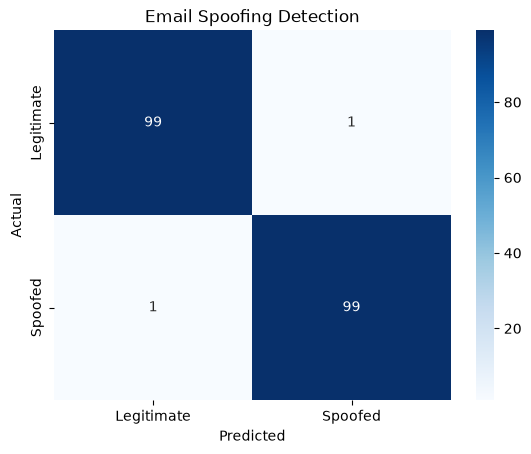

In [9]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Spoofed"],
    yticklabels=["Legitimate", "Spoofed"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Email Spoofing Detection")
plt.show()

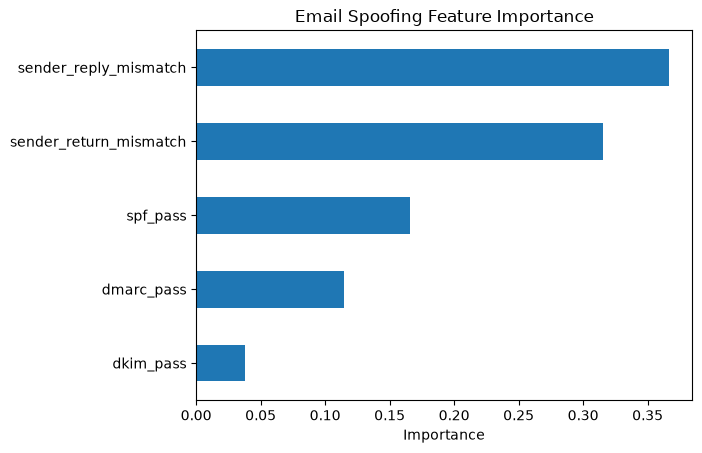

In [10]:
importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values()

importance.plot(kind="barh")

plt.title("Email Spoofing Feature Importance")
plt.xlabel("Importance")
plt.show()

In [11]:
new_email = pd.DataFrame([{
    "sender_return_mismatch": 1,
    "sender_reply_mismatch": 1,
    "spf_pass": 0,
    "dkim_pass": 0,
    "dmarc_pass": 0
}])

prediction = model.predict(new_email)[0]

if prediction == 1:
    print("Potentially SPOOFED email")
else:
    print("LEGITIMATE email")

Potentially SPOOFED email
